# Zambia's last ECF review, read by machine

In: IMF Country Report No. 26/21, the Sixth Review under the Extended Credit Facility.  
Out: checked summaries, an indicator record, cited answers and a dashboard.

**Install extras**  
In: nothing. Out: fixed library versions.

In [1]:
%pip install -q pdfplumber==0.11.10 cerberus==1.3.8 tinydb==4.9.0 stamina==26.1.0 python-dotenv==1.2.4 faiss-cpu==1.15.1

**Settings**  
In: one block written like a .env file. Out: `CFG`, read by every stage.

In [2]:
import bisect, hashlib, inspect, io, json, os, re, textwrap, time
from collections import Counter
from pathlib import Path

import cerberus
import faiss
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pdfplumber
import stamina
from dotenv import dotenv_values
from sentence_transformers import SentenceTransformer
from tinydb import Query, TinyDB
from transformers import AutoTokenizer

CFG = dotenv_values(stream=io.StringIO("""
PDF=data/IMF_CR_26_21_Zambia_Sixth_ECF_Review.pdf
COUNTRY=Zambia
FORECAST_YEAR=2026
STORE=cache/replies.json
OUT=results
WRITER=gemini-3.8-flash
JUDGE=gemini-3.7-flash
RIVALS=gemini-3.5-flash-lite,gemini-3.6-flash
SECRET=GEMINI_FREE_KEY
EMBEDDER=BAAI/bge-base-en-v1.5
QUERY_PREFIX=Represent this sentence for searching relevant passages:
WINDOW=420
STRIDE=50
NEIGHBOURS=6
HEAD_BAND=72
FOOT_BAND=745
WORD_LIMIT=100
BATCH=20
OUTPUT_CAP=16384
"""))
num = lambda key: float(CFG[key])
whole = lambda key: int(CFG[key])
OUT = Path(CFG["OUT"])
OUT.mkdir(exist_ok=True)
Path(CFG["STORE"]).parent.mkdir(exist_ok=True)


def dump(name, payload):
    """One result, one JSON file. A DataFrame is written as a list of records."""
    def convert(value):
        if isinstance(value, pd.DataFrame):
            return json.loads(value.to_json(orient="records"))
        if isinstance(value, np.generic):
            return value.item()
        raise TypeError(type(value))
    (OUT / f"{name}.json").write_text(json.dumps(payload, indent=1, default=convert), encoding="utf-8")
    return payload

**Pipes**  
In: plain functions. Out: stages that chain with `|`, sharing one dictionary called the run.

In [3]:
class Stage:
    def __init__(self, work, label=None):
        self.work, self.label = work, label or work.__name__

    def __or__(self, following):
        return Stage(lambda run: following.work(self.work(run)), f"{self.label} | {following.label}")

    def __call__(self, run):
        began = time.perf_counter()
        before = set(run)
        result = self.work(run)
        print(f"[{self.label}] {time.perf_counter() - began:.1f}s, added: {sorted(set(result) - before)}")
        return result


RUN = {}

**Reply rules**  
In: Cerberus rule tables. Out: a validator for each reply and the JSON schema sent to Gemini.

In [4]:
THEMES = ["Inflation & Prices", "Interest Rates & Credit", "Housing & Real Estate", "Banking Capital & Liquidity", "Sovereign Debt", "Labor Market Dynamics", "Systemic Financial Risk"]
FIELDS = ["gdp_growth_forecast_pct", "headline_inflation_rate_pct", "central_bank_policy_rate_pct", "non_performing_loan_ratio", "unemployment_rate_pct", "tier_1_capital_ratio"]
TEXT, MARK = {"type": "string"}, {"type": "integer", "min": 1, "max": 5}
MAYBE_TEXT, MAYBE_NUMBER, MAYBE_WHOLE = {"type": "string", "nullable": True}, {"type": "number", "nullable": True}, {"type": "integer", "nullable": True}
objects = lambda fields: {"type": "dict", "schema": fields}
items = lambda rule, **limits: {"type": "list", "schema": rule, **limits}
INSIGHT = objects({"label": TEXT, "explanation": TEXT, "pdf_page": {"type": "integer"}, "quote": TEXT})
READING = objects({"value": MAYBE_NUMBER, "year": MAYBE_WHOLE, "pdf_page": MAYBE_WHOLE, "evidence": MAYBE_TEXT, "reason": MAYBE_TEXT})

RULES = {
    "summary": {"summary": TEXT},
    "scorecard": {"consistency": MARK, "completeness": MARK, "factual_alignment": MARK, "faults": items(TEXT)},
    "briefing": {"bullets": items(objects({"section_id": TEXT, "sentence": TEXT}), minlength=6, maxlength=8)},
    "point_checks": {"checks": items(objects({"number": {"type": "integer"}, "supported": {"type": "boolean"}, "reason": TEXT}))},
    "theme_tags": {"tags": items(objects({"chunk_id": TEXT, "primary": {"type": "string", "allowed": THEMES + ["none"]}}))},
    "insights": {"strengths": items(INSIGHT, minlength=5, maxlength=7), "vulnerabilities": items(INSIGHT, minlength=5, maxlength=7)},
    "indicators": {field: READING for field in FIELDS},
    "audit": {"rows": items(objects({"field": {"type": "string", "allowed": FIELDS}, "verdict": {"type": "string", "allowed": ["CORRECT", "WRONG", "NOT_FOUND", "CORRECTLY_NULL", "MISSED"]}, "page_shows": MAYBE_NUMBER, "reason": TEXT}))},
    "trend_picks": {"picks": items(objects({"label": TEXT, "why": TEXT}), minlength=6, maxlength=10)},
    "answer": {"answer": TEXT, "citations": items(TEXT), "answerable": {"type": "boolean"}},
    "answer_score": {"faithfulness": MARK, "completeness": MARK, "faithfulness_reason": TEXT, "completeness_reason": TEXT},
}


def json_schema(rule):
    """Translate one Cerberus rule table into a JSON schema."""
    if "type" not in rule:
        return {"type": "object", "properties": {k: json_schema(v) for k, v in rule.items()}, "required": list(rule)}
    if rule["type"] == "dict":
        return json_schema(rule["schema"])
    if rule["type"] == "list":
        return {"type": "array", "items": json_schema(rule["schema"])}
    out = {"type": rule["type"]}
    if "allowed" in rule:
        out["enum"] = rule["allowed"]
    return {"anyOf": [out, {"type": "null"}]} if rule.get("nullable") else out


def rule_errors(kind, reply):
    checker = cerberus.Validator(RULES[kind], require_all=True, allow_unknown=False)
    return [] if checker.validate(reply) else [str(checker.errors)[:300]]

**Prompts**  
In: one small function per prompt. Out: a system instruction and a user message, also saved as a prompt book.

In [5]:
PROMPT = {}


def prompt(fn):
    PROMPT[fn.__name__] = fn
    return fn


@prompt
def summarise(title, span, text, note):
    return ("You brief a sovereign debt analyst on IMF programme documents. Use only the text given. Keep figures with their year and unit, and say who holds each view: staff, the authorities, or the Executive Board.",
            f"Section: {title} (pages {span}).\nIn 70 to 90 words, state what this section reports and what it asks the authorities to do. One paragraph.\n{note}\nTEXT:\n{text}")


@prompt
def score_summary(title, text, summary):
    return ("You audit summaries of IMF documents. Mark from 1 to 5. Start from 3 and raise a mark only for what you verified. A figure with the wrong year or unit, or a commitment credited to the wrong party, caps factual_alignment at 2. List every fault.",
            f"SOURCE ({title}):\n{text}\n\nSUMMARY:\n{summary}")


@prompt
def brief(digest, note):
    return ("You write the opening page of a financial stability note. Every bullet states a finding or a risk judgement in one sentence.",
            f"Using these section summaries, write 6 to 8 bullets on the main financial stability findings and the risk assessment of the whole document. Give the section_id behind each bullet.\n{note}\n{digest}")


@prompt
def check_points(points):
    return ("You test claims against source text. supported is true only if the source says it.", points)


@prompt
def tag_themes(themes, passages):
    return ("You sort passages of an IMF report by the one financial stability theme each is mostly about. Use none when no theme fits.", f"Themes: {themes}\n\n{passages}")


@prompt
def find_insights(country, text, note):
    return ("You extract growth drivers and vulnerabilities from IMF reports. Each item must rest on a sentence copied exactly from the given pages.",
            f"For {country}, give 5 to 7 strengths or growth drivers and 5 to 7 systemic vulnerabilities: a short label, one sentence of explanation, the page in the tag, and an exact quote of 8 to 25 words.\n{note}\n{text}")


@prompt
def read_indicators(year, text):
    return ("You copy macro-financial indicators from IMF tables and text into JSON. Copy each number exactly. If an indicator is not stated in these pages, return null for value, year, pdf_page and evidence, and give the reason.",
            f"""Definitions:
gdp_growth_forecast_pct: real GDP growth projected for {year}, the first projection year in the main indicator table.
headline_inflation_rate_pct: annual average inflation projected for {year}, not the end-of-year rate.
central_bank_policy_rate_pct: the latest monetary policy rate stated.
non_performing_loan_ratio: NPLs or past due advances as percent of total loans, latest period.
unemployment_rate_pct: the national unemployment rate, latest period.
tier_1_capital_ratio: Tier 1 regulatory capital to risk-weighted assets, latest period, not total regulatory capital.
Use the number in the page tag for pdf_page and copy the row or sentence into evidence.

{text}""")


@prompt
def audit_indicators(extracted, text):
    return ("You audit extracted indicators against source pages, field by field. CORRECT if the page shows that value for that definition and period; WRONG if it shows another value; NOT_FOUND if you cannot locate it; CORRECTLY_NULL if null and truly absent; MISSED if null but present. Put the value you see in page_shows.",
            f"EXTRACTED:\n{extracted}\n\nPAGES:\n{text}")


@prompt
def pick_trends(labels):
    return ("You pick data series for charts of a country's macro-financial path.", f"Choose 6 to 10 rows that together show growth, prices, public finances, debt and bank health over time. Copy each label exactly.\n{labels}")


@prompt
def answer_question(question, context):
    return ("You answer questions on an IMF report using only the numbered passages, and cite the ids you used. If they do not hold the answer, set answerable to false and say so.",
            f"QUESTION: {question}\n\nPASSAGES:\n{context}")


@prompt
def score_answer(question, context, answer):
    return ("You grade an answer against its passages. faithfulness 5: every claim is in the passages. completeness 5: the question is fully answered. If the question cannot be answered from the passages, an answer saying so earns 5 for faithfulness and at most 3 for completeness when the passages only partly address it.",
            f"QUESTION: {question}\n\nPASSAGES:\n{context}\n\nANSWER:\n{answer}")


def prompt_book():
    return {name: dict(zip(("system", "user"), fn(*[f"<{p}>" for p in inspect.signature(fn).parameters]))) for name, fn in PROMPT.items()}

**Model calls and stored replies**  
In: a request. Out: a validated reply, taken from TinyDB when the same request was seen before.

In [6]:
LOG = []
STORE, ROW = TinyDB(CFG["STORE"], sort_keys=True, indent=0), Query()
live = {"client": None, "key": ""}


class Transient(Exception):
    """A fault worth waiting out: rate limits, server errors, cut-off or empty replies."""


def secret():
    """Asked for only when a reply is not stored, so a stored run never touches the key."""
    if not live["key"]:
        try:
            from google.colab import userdata
            live["key"] = userdata.get(CFG["SECRET"]) or ""
        except Exception:
            live["key"] = os.environ.get(CFG["SECRET"], "")
    return live["key"]


@stamina.retry(on=Transient, attempts=6, wait_initial=4.0, wait_max=90.0)
def gemini(model, system, user, schema, temperature):
    if not secret():
        raise RuntimeError(f"no stored reply and no key in {CFG['SECRET']}")
    from google import genai
    from google.genai import types
    live["client"] = live["client"] or genai.Client(api_key=live["key"])
    began = time.perf_counter()
    try:
        got = live["client"].models.generate_content(model=model, contents=user, config=types.GenerateContentConfig(
            system_instruction=system, temperature=temperature, max_output_tokens=whole("OUTPUT_CAP"), response_mime_type="application/json", response_json_schema=schema))
    except Exception as fault:
        if re.search(r"429|500|502|503|504|RESOURCE_EXHAUSTED|UNAVAILABLE|timed? ?out", str(fault), re.I):
            raise Transient(str(fault)[:200]) from fault
        raise
    if (got.candidates and "MAX_TOKENS" in str(got.candidates[0].finish_reason)) or not (got.text or "").strip():
        raise Transient("cut off or empty reply")
    use = got.usage_metadata
    return {"text": got.text, "seconds": round(time.perf_counter() - began, 2), "tokens_in": use.prompt_token_count or 0, "tokens_out": use.candidates_token_count or 0}


def fetch(step, model, system, user, schema, temperature):
    key = hashlib.md5(json.dumps([model, system, user, schema, temperature], sort_keys=True).encode()).hexdigest()
    row, origin = STORE.get(ROW.key == key), "stored"
    if row is None:
        row, origin = {"key": key, **gemini(model, system, user, schema, temperature)}, "live"
        STORE.insert(row)
    LOG.append({"step": step, "model": model, "origin": origin, **{k: row[k] for k in ("seconds", "tokens_in", "tokens_out")}})
    return row


def ask(step, role, template, kind, test=None, model=None, **slots):
    """Call the model. A reply that breaks the rules goes back with the reasons, at most twice."""
    model = model or CFG["JUDGE" if role == "judge" else "WRITER"]
    system, user = PROMPT[template](**slots)
    problems = []
    for attempt in (0, 1, 2):
        message = user + (f"\n\nYour last reply was rejected: {'; '.join(problems)}. Send a corrected reply." if problems else "")
        row = fetch(step + ("+redo" if attempt else ""), model, system, message, json_schema(RULES[kind]), 0.0 if role == "judge" else 0.15)
        try:
            reply = json.loads(row["text"])
        except json.JSONDecodeError as fault:
            problems = [f"not valid JSON: {fault}"]
            continue
        problems = rule_errors(kind, reply) or (test(reply) if test else [])
        if not problems:
            return reply
    raise RuntimeError(f"{step}: {problems}")

**Read the pages**  
In: the PDF. Out: cleaned page text with its position, after cropping the header and footer bands.

In [7]:
SWAP = str.maketrans({"\ufb01": "fi", "\ufb02": "fl", "\u2018": "'", "\u2019": "'", "\u201c": '"', "\u201d": '"', "\u2013": "-", "\u2014": "-", "\u2010": "-", "\u2011": "-", "\u2212": "-", "\u00ad": "", "\u00a0": " ", "\u2022": "*", "\u0080": "*", "\uf0b7": "*"})
OPENS_NEW = re.compile(r"^(?:\d{1,3}\.\s|[a-z]\.\s|[A-Z]\.\s|\*\s|\(\w\)\s)")
TALLY = Counter()


def is_table(lines):
    return sum(len(re.findall(r"(?:^| )-?\d[\d,]*\.\d(?= |$)", t)) >= 4 for _, t, _ in lines) >= 7


def paragraphs(lines):
    """Rejoin wrapped lines. A new paragraph starts at a list mark or after a short closing line."""
    out = []
    for top, text, width in lines:
        last = out[-1] if out else None
        if last and not OPENS_NEW.match(text) and not (last[1].endswith((".", ":", ";")) and width < 300):
            if last[1].endswith("-") and text[:1].islower():
                last[1] = last[1][:-1] + text
                TALLY["hyphen breaks joined"] += 1
            else:
                last[1] += " " + text
            TALLY["wrapped lines joined"] += 1
        else:
            out.append([top, text])
    return [tuple(p) for p in out]


def headings(found, number):
    """Large bold lines are titles. A title that wraps is merged with its next line."""
    titles = []
    for line in found:
        first = line["chars"][0]
        size, bold = round(first["size"], 1), "Bold" in first["fontname"]
        if bold and size >= 12 and len(line["text"]) > 3:
            if titles and titles[-1]["size"] == size and line["top"] - titles[-1]["tail"] < 30:
                titles[-1].update(text=f"{titles[-1]['text']} {line['text'].translate(SWAP)}", tail=line["top"])
            else:
                titles.append({"page": number, "size": size, "top": line["top"], "tail": line["top"], "text": line["text"].translate(SWAP)})
    return titles


def read_pages(run):
    pages = []
    with pdfplumber.open(CFG["PDF"]) as pdf:
        for number, page in enumerate(pdf.pages, 1):
            crop = page.crop((0, num("HEAD_BAND"), page.width, min(num("FOOT_BAND"), page.height)))
            found = crop.extract_text_lines(return_chars=True)
            TALLY["lines in header and footer bands removed"] += len(page.extract_text_lines()) - len(found)
            lines = [(l["top"], l["text"].translate(SWAP), l["x1"] - l["x0"]) for l in found]
            figure = bool(lines) and bool(re.match(r"(Text )?Figures? \d*", " ".join(t for _, t, _ in lines[:2])))
            table = is_table(lines)
            if figure and not table:
                kept = [l for l in lines if len(re.findall(r"[A-Za-z]{3,}", l[1])) >= 5]
                TALLY["chart labels dropped"] += len(lines) - len(kept)
                lines = kept
            parts = [(top, text) for top, text, _ in lines] if table else paragraphs(lines)
            pages.append({"page": number, "kind": "table" if table else "figure" if figure else "prose", "parts": parts, "rows": [t for _, t, _ in lines] if table else [],
                          "text": "\n".join(t for _, t in parts), "titles": headings(found, number)})
    print(Counter(p["kind"] for p in pages), dict(TALLY))
    return {**run, "pages": pages}


read_pages = Stage(read_pages)


def tagged(pages, numbers):
    return "\n\n".join(f"[PAGE {n}]\n{pages[n - 1]['text']}" for n in numbers)


RUN = read_pages(RUN)

Counter({'prose': 109, 'figure': 17, 'table': 14}) {'lines in header and footer bands removed': 236, 'wrapped lines joined': 3603, 'hyphen breaks joined': 42, 'chart labels dropped': 347}
[read_pages] 42.1s, added: ['pages']


**Find the sections**  
In: title lines. Out: sections with their pages. Definitions in the Technical Memorandum are kept for search but not summarised.

In [8]:
BANNER = re.compile(r"^(ZAMBIA$|CONTENTS|Washington|QUANTITATIVE PERFORMANCE|CONTINUOUS PERFORMANCE|MONETARY POLICY CONSULTATION|INDICATIVE TARGETS|MONITORING AND REPORTING|Definition)")
QUIET = re.compile(r"^(SIXTH REVIEW|NONOBSERVANCE|Attachment II|References)", re.I)


def find_sections(run):
    """The policy memorandum and the debt analysis stay whole, so their inner headings are skipped."""
    pages, marks, scope = run["pages"], [], ""
    for title in (t for p in pages for t in p["titles"]):
        text = title["text"]
        if BANNER.match(text):
            continue
        if text.startswith("Attachment"):
            scope = "memo"
        elif title["size"] == 14.5 and "DEBT SUSTAINABILITY" in text:
            scope, title = "dsa", {**title, "text": "Debt Sustainability Analysis"}
        elif title["size"] == 15.0 or text.startswith("Statement by"):
            scope = ""
        elif scope or title["size"] < 13:
            continue
        marks.append(title)
    first_figure = next(p["page"] for p in pages if p["page"] > 26 and re.match(r"Figure \d", p["text"]))
    marks = sorted(marks + [{"page": first_figure, "top": 0, "text": "Figures and Tables", "size": 18.0}], key=lambda m: (m["page"], m["top"]))
    sections = []
    for i, mark in enumerate(marks):
        stop = marks[i + 1] if i + 1 < len(marks) else None
        parts = [(n, t) for n in range(mark["page"], (stop["page"] if stop else len(pages)) + 1) for top, t in pages[n - 1]["parts"]
                 if (n > mark["page"] or top >= mark["top"] - 4) and (not stop or n < stop["page"] or top < stop["top"] - 4) and "____" not in t]
        text = "\n".join(t for _, t in parts)
        if not parts:
            continue
        sections.append({"sid": f"S{len(sections) + 1:02d}", "title": mark["text"][:100], "pages": sorted({n for n, _ in parts}), "parts": parts, "text": text, "summarise": len(text) > 700 and not QUIET.match(mark["text"])})
    return {**run, "sections": sections}


find_sections = Stage(find_sections)
RUN = find_sections(RUN)
outline = pd.DataFrame(RUN["sections"]).assign(first=lambda d: d.pages.str[0], last=lambda d: d.pages.str[-1], chars=lambda d: d.text.str.len())[["sid", "title", "first", "last", "chars", "summarise"]]
outline

[find_sections] 0.0s, added: ['sections']


,sid,title,first,last,chars,summarise
0,S01,NONOBSERVANCE OF A QUANTITATIVE PERFORMANCE CR...,1,2,1454,False
1,S02,IMF Executive Board Completes Sixth Review Und...,2,6,9065,True
2,S03,EXECUTIVE SUMMARY,7,9,2165,True
3,S04,CONTEXT,10,11,6320,True
4,S05,RECENT ECONOMIC DEVELOPMENTS,11,15,12126,True
5,S06,PROGRAM PERFORMANCE,16,16,2713,True
6,S07,OUTLOOK AND RISKS,17,18,4913,True
7,S08,POLICY DISCUSSIONS,18,18,696,False
8,S09,A. Supporting Fiscal and Debt Sustainability,18,21,9992,True
9,S10,"B. Safeguarding Price, External, and Financial...",21,22,3921,True


**Cut into windows**  
In: section text. Out: windows of 420 tokens with a 50 token stride, made by the embedder's fast tokenizer.

In [9]:
tokenizer = AutoTokenizer.from_pretrained(CFG["EMBEDDER"], model_max_length=10**6)


def cut_windows(run):
    windows = []
    for section in run["sections"]:
        if len(section["text"]) < 200 or re.match(r"^References|^SIXTH REVIEW", section["title"], re.I):
            continue
        text, starts, pages = "", [], []
        for number, part in section["parts"]:
            starts.append(len(text))
            pages.append(number)
            text += part + "\n"
        coded = tokenizer(text, add_special_tokens=False, truncation=True, max_length=whole("WINDOW"), stride=whole("STRIDE"), return_overflowing_tokens=True, return_offsets_mapping=True)
        for ids, spans in zip(coded["input_ids"], coded["offset_mapping"]):
            first, last = spans[0][0], spans[-1][1]
            on = sorted(set(pages[bisect.bisect_right(starts, first) - 1:bisect.bisect_left(starts, last)]))
            windows.append({"sid": section["sid"], "title": section["title"], "pages": on, "tokens": len(ids), "text": text[first:last].strip()})
    for i, window in enumerate(windows, 1):
        window["id"] = f"W{i:03d}"
    return {**run, "windows": windows}


cut_windows = Stage(cut_windows)
RUN = cut_windows(RUN)
dump("chunks", RUN["windows"])
pd.Series([w["tokens"] for w in RUN["windows"]]).describe().round(1).to_frame("tokens").T

[cut_windows] 0.2s, added: ['windows']


,count,mean,std,min,25%,50%,75%,max
tokens,258.0,402.5,61.3,78.0,420.0,420.0,420.0,420.0


**Summarise and mark each section**  
In: sections. Out: summaries under 100 words, each marked by the judge, checked by code and redone once if faulted.

In [10]:
figures_in = lambda text: set(re.findall(r"\d+(?:\.\d+)?", text.replace(",", "")))
not_in_source = lambda claim, source: sorted(figures_in(claim) - figures_in(source))
squeeze = lambda text: re.sub(r"[^a-z0-9]", "", text.lower())
within_limit = lambda reply: [] if len(reply["summary"].split()) < whole("WORD_LIMIT") else [f"use fewer than {whole('WORD_LIMIT')} words"]
total = lambda card: card["consistency"] + card["completeness"] + card["factual_alignment"]


def attempt(section, suffix="", note=""):
    span = f"{section['pages'][0]}-{section['pages'][-1]}"
    text = ask(f"summary:{section['sid']}{suffix}", "writer", "summarise", "summary", test=within_limit, title=section["title"], span=span, text=section["text"], note=note)["summary"]
    card = ask(f"mark:{section['sid']}{suffix}", "judge", "score_summary", "scorecard", title=section["title"], text=section["text"], summary=text)
    return text, card, not_in_source(text, section["text"])


def summarise_sections(run):
    rows = []
    for section in (s for s in run["sections"] if s["summarise"]):
        text, card, stray = attempt(section)
        first = dict(card, stray=stray, text=text)
        redone = False
        if min(card["consistency"], card["completeness"], card["factual_alignment"]) < 4 or stray or card["faults"]:
            reasons = card["faults"] + [f"{x} is not in the source" for x in stray]
            again, again_card, again_stray = attempt(section, ":redo", "An earlier draft had these problems, which you must fix: " + "; ".join(reasons) + "\nEarlier draft: " + text)
            if not again_stray and total(again_card) >= total(card):
                text, card, stray, redone = again, again_card, again_stray, True
        rows.append({"sid": section["sid"], "title": section["title"], "pages": f"{section['pages'][0]}-{section['pages'][-1]}", "summary": text, "words": len(text.split()), "consistency": card["consistency"], "completeness": card["completeness"],
                     "factual_alignment": card["factual_alignment"], "faults": card["faults"], "stray_figures": stray, "redone": redone, "first_text": first["text"], "first_marks": [first["consistency"], first["completeness"], first["factual_alignment"]], "first_faults": first["faults"], "first_stray": first["stray"]})
    return {**run, "summaries": pd.DataFrame(rows)}


summarise_sections = Stage(summarise_sections)
RUN = summarise_sections(RUN)
marks = RUN["summaries"]
assert marks.words.max() < whole("WORD_LIMIT")
dump("section_summaries", marks)
print(f"{len(marks)} summaries, {marks.words.min()} to {marks.words.max()} words, {int(marks.redone.sum())} redone")
marks[["sid", "title", "words", "consistency", "completeness", "factual_alignment", "redone"]]

[summarise_sections] 0.1s, added: ['summaries']
25 summaries, 77 to 88 words, 6 redone


,sid,title,words,consistency,completeness,factual_alignment,redone
0,S02,IMF Executive Board Completes Sixth Review Und...,83,5,4,5,True
1,S03,EXECUTIVE SUMMARY,80,5,4,5,False
2,S04,CONTEXT,87,5,4,4,False
3,S05,RECENT ECONOMIC DEVELOPMENTS,82,5,4,5,False
4,S06,PROGRAM PERFORMANCE,88,5,4,4,True
5,S07,OUTLOOK AND RISKS,86,5,4,5,False
6,S09,A. Supporting Fiscal and Debt Sustainability,85,5,5,5,False
7,S10,"B. Safeguarding Price, External, and Financial...",82,5,4,5,False
8,S11,C. Enhancing Financial Stability Frameworks,88,5,4,5,False
9,S12,D. Advancing Structural Reforms to Boost Poten...,85,5,4,5,True


**Write the briefing**  
In: the summaries. Out: 6 to 8 bullets, each tested against the section it names.

In [11]:
def test_bullets(bullets, by_id):
    points = "\n\n".join(f"POINT {n}: {b['sentence']}\nSOURCE: {by_id[b['section_id']]['text']}" for n, b in enumerate(bullets, 1))
    return ask("briefing:test", "judge", "check_points", "point_checks", points=points)["checks"]


def write_briefing(run):
    by_id = {s["sid"]: s for s in run["sections"]}
    known = lambda reply: [f"unknown section {b['section_id']}" for b in reply["bullets"] if b["section_id"] not in by_id]
    digest = "\n".join(f"[{r.sid}] {r.title}: {r.summary}" for r in run["summaries"].itertuples())
    reply = ask("briefing", "writer", "brief", "briefing", test=known, digest=digest, note="")
    checks = test_bullets(reply["bullets"], by_id)
    rejected = [f"point {c['number']}: {c['reason']}" for c in checks if not c["supported"]]
    rejected += [f"point {n}: {x} is not in its section" for n, b in enumerate(reply["bullets"], 1) for x in not_in_source(b["sentence"], by_id[b["section_id"]]["text"])]
    if rejected:
        reply = ask("briefing:redo", "writer", "brief", "briefing", test=known, digest=digest, note="Correct or replace these rejected points: " + "; ".join(rejected))
        checks = test_bullets(reply["bullets"], by_id)
    return {**run, "briefing": {"bullets": reply["bullets"], "checks": checks, "first_rejected": rejected}}


write_briefing = Stage(write_briefing)
RUN = write_briefing(RUN)
dump("executive_summary", RUN["briefing"])
for bullet in RUN["briefing"]["bullets"]:
    print(f"* [{bullet['section_id']}] {bullet['sentence']}")

[write_briefing] 0.0s, added: ['briefing']
* [S26] Zambia's public debt remains sustainable but is assessed at high risk of debt distress, leaving medium-term stability reliant on achieving projected primary surpluses and completing remaining commercial debt restructurings.
* [S10] Safeguarding external and macroeconomic stability requires accelerated foreign exchange reserve accumulation alongside a carefully calibrated monetary policy stance to anchor inflation.
* [S11] Financial stability frameworks are progressing through enhanced surveillance and resolution mechanisms, though Bank of Zambia credit facilities require robust safeguards and exit strategies to mitigate central bank balance-sheet risks.
* [S18] The Risk Assessment Matrix rates recurrent climate shocks and debt restructuring delays as low-likelihood risks carrying less than a ten percent probability, contrasting with high-likelihood external threats.
* [S20] State-owned enterprises and public-private partnerships with c

**Count the themes**  
In: windows. Out: term counts and one model label per window for the seven themes.

In [12]:
TERMS = {
    "Inflation & Prices": r"inflation|disinflation|prices?|CPI",
    "Interest Rates & Credit": r"policy rates?|interest rates?|credit|lending|treasury bills?|yields?",
    "Housing & Real Estate": r"housing|real estate|mortgages?|property",
    "Banking Capital & Liquidity": r"banks?|banking|capital adequacy|liquidity|NPLs?|non-?performing|deposit insurance",
    "Sovereign Debt": r"debt|restructuring|bondholders?|creditors?|DSA|arrears",
    "Labor Market Dynamics": r"labou?r|employment|jobs?|wages?|workers?",
    "Systemic Financial Risk": r"financial stability|systemic|contagion|stress tests?|resolution|macroprudential",
}
COMPILED = {theme: re.compile(rf"\b(?:{words})\b", re.I) for theme, words in TERMS.items()}


def count_themes(run):
    windows, labels = run["windows"], Counter()
    hits = {theme: sum(len(pattern.findall(w["text"])) for w in windows) for theme, pattern in COMPILED.items()}
    for start in range(0, len(windows), whole("BATCH")):
        group = windows[start:start + whole("BATCH")]
        wanted = {w["id"] for w in group}
        every = lambda reply: [] if {t["chunk_id"] for t in reply["tags"]} == wanted else ["label each passage once, using its id"]
        passages = "\n\n".join(f"<{w['id']}> {w['text'][:900]}" for w in group)
        labels.update(t["primary"] for t in ask(f"themes:{start // whole('BATCH'):02d}", "writer", "tag_themes", "theme_tags", test=every, themes="; ".join(THEMES), passages=passages)["tags"])
    table = pd.DataFrame({"theme": THEMES, "term_hits": [hits[t] for t in THEMES], "windows_labelled": [labels[t] for t in THEMES]})
    table["term_share"] = (100 * table.term_hits / table.term_hits.sum()).round(1)
    table["label_share"] = (100 * table.windows_labelled / max(table.windows_labelled.sum(), 1)).round(1)
    return {**run, "themes": {"table": table, "no_theme": labels["none"], "rank_agreement": round(float(table.term_hits.corr(table.windows_labelled, method="spearman")), 3)}}


count_themes = Stage(count_themes)
RUN = count_themes(RUN)
dump("theme_counts", RUN["themes"])
print("rank agreement:", RUN["themes"]["rank_agreement"], "| windows with no theme:", RUN["themes"]["no_theme"])
RUN["themes"]["table"]

[count_themes] 0.1s, added: ['themes']
rank agreement: 0.764 | windows with no theme: 139


,theme,term_hits,windows_labelled,term_share,label_share
0,Inflation & Prices,252,8,13.8,6.7
1,Interest Rates & Credit,166,10,9.1,8.4
2,Housing & Real Estate,7,0,0.4,0.0
3,Banking Capital & Liquidity,249,5,13.6,4.2
4,Sovereign Debt,1043,88,57.0,73.9
5,Labor Market Dynamics,10,0,0.5,0.0
6,Systemic Financial Risk,102,8,5.6,6.7


**Strengths and vulnerabilities**  
In: the press release, executive summary, appraisal and risk matrix. Out: quoted items, with each quote confirmed on its page.

In [13]:
def extract_insights(run):
    pages = run["pages"]
    chosen = sorted({n for s in run["sections"] if re.match(r"IMF Executive Board|EXECUTIVE SUMMARY|STAFF APPRAISAL|Annex III", s["title"]) for n in s["pages"]})
    def quotes_on_page(reply):
        return [f"the quote for {i['label']} is not word for word on page {i['pdf_page']}; quote one sentence of running text, not a table" for kind in ("strengths", "vulnerabilities") for i in reply[kind]
                if not 1 <= i["pdf_page"] <= len(pages) or squeeze(i["quote"]) not in squeeze(pages[i["pdf_page"] - 1]["text"])]
    reply = ask("insights", "writer", "find_insights", "insights", test=quotes_on_page, country=CFG["COUNTRY"], text=tagged(pages, chosen), note="")
    listed = [("strength", i) for i in reply["strengths"]] + [("vulnerability", i) for i in reply["vulnerabilities"]]
    points = "\n".join(f"POINT {n} (claimed {kind}): {i['label']}. {i['explanation']} QUOTE: {i['quote']}" for n, (kind, i) in enumerate(listed, 1))
    return {**run, "insights": {**reply, "checks": ask("insights:test", "judge", "check_points", "point_checks", points=points)["checks"], "pages_read": chosen}}


extract_insights = Stage(extract_insights)
RUN = extract_insights(RUN)
dump("strengths_vulnerabilities", RUN["insights"])
print(sum(c["supported"] for c in RUN["insights"]["checks"]), "of", len(RUN["insights"]["checks"]), "supported")
pd.DataFrame([{"kind": k, "label": i["label"], "page": i["pdf_page"]} for k in ("strengths", "vulnerabilities") for i in RUN["insights"][k]])

[extract_insights] 0.0s, added: ['insights']
9 of 12 supported


,kind,label,page
0,strengths,Mining and Agriculture Performance,2
1,strengths,Electricity and Services Recovery,2
2,strengths,Progress on Debt Restructuring,3
3,strengths,Financial Safety Net Enhancements,3
4,strengths,Agricultural Sector Predictability,3
5,strengths,Strengthened Investor Confidence,6
6,vulnerabilities,High Risk of Debt Distress,3
7,vulnerabilities,Socio-Economic and Political Exposure,6
8,vulnerabilities,Foreign Exchange Shortfall,6
9,vulnerabilities,Persistent Inflationary Pressures,6


**Build the search index**  
In: windows. Out: unit vectors in a FAISS IndexFlatL2, so L2 order matches cosine order.

In [14]:
def build_index(run):
    model = SentenceTransformer(CFG["EMBEDDER"])
    texts = [w["text"] for w in run["windows"]]
    tag = hashlib.md5(json.dumps([CFG["EMBEDDER"], texts]).encode()).hexdigest()[:12]
    path = Path(CFG["STORE"]).parent / f"vectors_{tag}.npy"
    vectors = np.load(path) if path.exists() else model.encode(texts, normalize_embeddings=True, batch_size=16, show_progress_bar=False).astype("float32")
    np.save(path, vectors)
    flat = faiss.IndexFlatL2(vectors.shape[1])
    flat.add(vectors)
    return {**run, "embedder": model, "flat": flat}


def nearest(run, question, k):
    query = run["embedder"].encode([f"{CFG['QUERY_PREFIX']} {question}"], normalize_embeddings=True).astype("float32")
    distances, found = run["flat"].search(query, k)
    return [{**run["windows"][i], "distance": round(float(d), 4)} for d, i in zip(distances[0], found[0])]


build_index = Stage(build_index)
RUN = build_index(RUN)
print(RUN["flat"].ntotal, "vectors of size", RUN["flat"].d)

[build_index] 1.3s, added: ['embedder', 'flat']
258 vectors of size 768


**Read the tables by rule**  
In: table pages. Out: rows parsed without a model, which later test the model's numbers.

In [15]:
CELL = re.compile(r"^(?:-?\d[\d,]*(?:\.\d+)?|\.\.\.|\u2026)$")


def parse_rows(page):
    header, rows = None, {}
    for line in page["rows"]:
        words = line.split()
        years = [int(w) for w in words if re.fullmatch(r"20\d\d", w)]
        if header is None and len(years) >= 6:
            header = years
            continue
        values = []
        while words and CELL.match(words[-1]):
            values.insert(0, words.pop())
        if header and words and len(values) == len(header):
            rows[" ".join(words)] = [None if v in ("...", "\u2026") else float(v.replace(",", "")) for v in values]
    return pd.DataFrame(rows, index=header).T


def value_in(table, start, year):
    label = next(x for x in table.index if x.startswith(start))
    return float(table.loc[label, year])


def read_tables(run):
    pages = run["pages"]
    macro_page = next(p for p in pages if "Selected Economic Indicators" in p["text"] and p["kind"] == "table")
    bank_page = next(p for p in pages if "Financial Soundness Indicators" in p["text"] and p["kind"] == "table")
    macro, banks = parse_rows(macro_page), parse_rows(bank_page)
    year, bank_year = whole("FORECAST_YEAR"), max(banks.columns)
    rate_page = next(p for p in pages if re.search(r"policy rate[^.]{0,60}to (\d+(?:\.\d+)?) percent", p["text"]))
    rate = float(re.search(r"policy rate[^.]{0,60}to (\d+(?:\.\d+)?) percent", rate_page["text"])[1])
    says_unemployment = any(re.search(r"unemployment", p["text"], re.I) for p in pages)
    truth = {"gdp_growth_forecast_pct": (value_in(macro, "Real GDP growth", year), macro_page["page"]), "headline_inflation_rate_pct": (value_in(macro, "Inflation annual average", year), macro_page["page"]),
             "central_bank_policy_rate_pct": (rate, rate_page["page"]), "non_performing_loan_ratio": (value_in(banks, "Past due advances (NPL)", bank_year), bank_page["page"]),
             "unemployment_rate_pct": (None if not says_unemployment else float("nan"), None), "tier_1_capital_ratio": (value_in(banks, "Tier 1 regulatory capital", bank_year), bank_page["page"])}
    return {**run, "macro": macro, "banks": banks, "truth": truth, "table_pages": [macro_page["page"], bank_page["page"]]}


read_tables = Stage(read_tables)
RUN = read_tables(RUN)
RUN["banks"].iloc[:6, -5:]

[read_tables] 0.0s, added: ['banks', 'macro', 'table_pages', 'truth']


,2021,2022,2023,2024,2025
Regulatory capital to risk-weighted assets,24.7,22.8,23.5,24.4,24.5
Tier 1 regulatory capital to risk-weighted assets,23.3,21.9,22.8,23.0,23.2
Capital to total assets,10.9,10.6,11.3,12.2,12.5
Past due advances (NPL) to total advances,5.8,5.0,4.2,4.1,3.5
Loan loss provisions to non-performing loans,102.8,93.4,92.2,91.2,99.2
Bad debt provisions to advances,6.0,4.4,3.6,3.4,3.3


**Extract the indicators**  
In: table pages and the nearest text. Out: the target JSON, with null and a reason when the report does not state a value.

In [16]:
LOOK_FOR = {"gdp_growth_forecast_pct": "real GDP growth projection", "headline_inflation_rate_pct": "average inflation projection", "central_bank_policy_rate_pct": "Bank of Zambia monetary policy rate decision",
            "non_performing_loan_ratio": "non-performing loans ratio of banks", "unemployment_rate_pct": "unemployment rate", "tier_1_capital_ratio": "Tier 1 regulatory capital of banks"}
reason_needed = lambda reply: [f"{f}: null needs a reason" for f in FIELDS if reply[f]["value"] is None and not reply[f]["reason"]]
as_record = lambda reply: {"country_name": CFG["COUNTRY"], **{f: (None if reply[f]["value"] is None else float(reply[f]["value"])) for f in FIELDS}}


def pages_to_read(run):
    return sorted(set(run["table_pages"]) | {hit["pages"][0] for query in LOOK_FOR.values() for hit in nearest(run, query, 2)})


def extract(run, numbers, step, model=None):
    return ask(step, "writer", "read_indicators", "indicators", test=reason_needed, model=model, year=whole("FORECAST_YEAR"), text=tagged(run["pages"], numbers))


def extract_indicators(run):
    numbers = pages_to_read(run)
    reply = extract(run, numbers, "indicators")
    verdicts = {r["field"]: r for r in ask("indicators:audit", "judge", "audit_indicators", "audit", extracted=json.dumps(as_record(reply)), text=tagged(run["pages"], numbers))["rows"]}
    table = pd.DataFrame([{"field": f, "value": reply[f]["value"], "year": reply[f]["year"], "page": reply[f]["pdf_page"], "table_value": run["truth"][f][0], "table_page": run["truth"][f][1], "code_agrees": reply[f]["value"] == run["truth"][f][0],
                           "judge": verdicts.get(f, {}).get("verdict"), "judge_saw": verdicts.get(f, {}).get("page_shows"), "evidence": reply[f]["evidence"], "fallback_reason": reply[f]["reason"]} for f in FIELDS])
    return {**run, "record": as_record(reply), "indicator_table": table, "pages_read": numbers}


extract_indicators = Stage(extract_indicators)
RUN = extract_indicators(RUN)
dump("indicators", RUN["record"])
dump("indicators_provenance", {"pages_read": RUN["pages_read"], "rows": RUN["indicator_table"]})
print(json.dumps(RUN["record"], indent=1))
RUN["indicator_table"][["field", "value", "year", "page", "table_value", "code_agrees", "judge"]]

[extract_indicators] 0.5s, added: ['indicator_table', 'pages_read', 'record']
{
 "country_name": "Zambia",
 "gdp_growth_forecast_pct": 5.8,
 "headline_inflation_rate_pct": 9.3,
 "central_bank_policy_rate_pct": 14.25,
 "non_performing_loan_ratio": 3.5,
 "unemployment_rate_pct": null,
 "tier_1_capital_ratio": 23.2
}


,field,value,year,page,table_value,code_agrees,judge
0,gdp_growth_forecast_pct,5.80,2026.0,4.0,5.80,True,CORRECT
1,headline_inflation_rate_pct,9.30,2026.0,4.0,9.30,True,CORRECT
2,central_bank_policy_rate_pct,14.25,2025.0,115.0,14.25,True,CORRECT
3,non_performing_loan_ratio,3.50,2025.0,40.0,3.50,True,CORRECT
4,unemployment_rate_pct,NaN,NaN,NaN,NaN,True,CORRECTLY_NULL
5,tier_1_capital_ratio,23.20,2025.0,40.0,23.20,True,CORRECT


**Compare with a hand reading**  
In: values read from the PDF by eye. Out: a comparison table. These values are used nowhere else.

In [17]:
BY_HAND = {"gdp_growth_forecast_pct": (5.8, 4), "headline_inflation_rate_pct": (9.3, 4), "central_bank_policy_rate_pct": (14.25, 12), "non_performing_loan_ratio": (3.5, 40), "unemployment_rate_pct": (None, None), "tier_1_capital_ratio": (23.2, 40)}
hand_view = RUN["indicator_table"][["field", "value", "table_value", "judge"]].assign(by_hand=lambda d: d.field.map(lambda f: BY_HAND[f][0]), pdf_page=lambda d: d.field.map(lambda f: BY_HAND[f][1]))
hand_view["match"] = [(pd.isna(a) and pd.isna(b)) or a == b for a, b in zip(hand_view.value, hand_view.by_hand)]
dump("hand_checks", hand_view)
hand_view

,field,value,table_value,judge,by_hand,pdf_page,match
0,gdp_growth_forecast_pct,5.80,5.80,CORRECT,5.80,4.0,True
1,headline_inflation_rate_pct,9.30,9.30,CORRECT,9.30,4.0,True
2,central_bank_policy_rate_pct,14.25,14.25,CORRECT,14.25,12.0,True
3,non_performing_loan_ratio,3.50,3.50,CORRECT,3.50,40.0,True
4,unemployment_rate_pct,NaN,NaN,CORRECTLY_NULL,NaN,NaN,True
5,tier_1_capital_ratio,23.20,23.20,CORRECT,23.20,40.0,True


**Trends over time**  
In: parsed rows. Out: long format through `pd.melt`. The writer picks the rows, and every value comes from the parser.

In [18]:
def find_trends(run):
    tables = {"macro": run["macro"], "banks": run["banks"]}
    known = [label for table in tables.values() for label in table.index]
    genuine = lambda reply: [f"unknown label: {p['label']}" for p in reply["picks"] if p["label"] not in known]
    picks = ask("trends", "writer", "pick_trends", "trend_picks", test=genuine, labels="\n".join(known))["picks"]
    chosen = {p["label"] for p in picks}
    frames = [table.loc[[l for l in table.index if l in chosen]].rename_axis("series").reset_index().melt(id_vars="series", var_name="year", value_name="value").assign(source=name) for name, table in tables.items()]
    return {**run, "trends": {"picks": picks, "long": pd.concat(frames, ignore_index=True).dropna(subset="value")}}


find_trends = Stage(find_trends)
RUN = find_trends(RUN)
dump("time_series", RUN["trends"])
RUN["trends"]["long"].groupby("series").agg(first_year=("year", "min"), last_year=("year", "max"), points=("value", "size"))

[find_trends] 0.0s, added: ['trends']


,first_year,last_year,points
series,,,
Credit to private sector (% change),2021,2027,7
"Fiscal balance (cash basis, % GDP)",2021,2027,7
Inflation annual average (%),2021,2027,7
Liquid assets to total deposits,2015,2025,11
Past due advances (NPL) to total advances,2015,2025,11
Public debt (% GDP),2021,2027,7
Real GDP growth (%),2021,2027,7
Regulatory capital to risk-weighted assets,2015,2025,11


**Answer questions with citations**  
In: questions and their six nearest windows. Out: cited answers, judged and tested against pages read by hand. Question 11 has no answer in the report.

In [19]:
QUESTIONS = [
    ("Q01", "What real GDP growth does staff project for 2025 and 2026, and what drives it?", [2, 17, 26, 72]),
    ("Q02", "Which quantitative performance criterion was missed and why was a waiver requested?", [2, 16, 27, 69]),
    ("Q03", "What did the Bank of Zambia decide on the policy rate in November 2025 and why?", [12, 70, 138]),
    ("Q04", "How is Zambia's risk of debt distress rated and is debt considered sustainable?", [3, 17, 109, 121, 122, 123]),
    ("Q05", "How are the fuel-related arrears being repaid?", [14, 15]),
    ("Q06", "What fiscal costs does the Food Reserve Agency create and what reforms are committed?", [50, 51, 52]),
    ("Q07", "What is the plan for solar power in diversifying the energy mix?", [45, 46, 47, 48]),
    ("Q08", "How strong are bank capital and asset quality?", [14, 40, 72]),
    ("Q09", "How should the fiscal framework handle rising mining revenues?", [55, 56, 57]),
    ("Q10", "What do the revised banking law and the deposit insurance framework change?", [61, 63, 87]),
    ("Q11", "What is Zambia's national unemployment rate?", []),
]


def respond(run, qid, question, gold, model=None, suffix=""):
    hits = nearest(run, question, whole("NEIGHBOURS"))
    context = "\n\n".join(f"[{h['id']}] (pages {h['pages']}) {h['text']}" for h in hits)
    known = {h["id"] for h in hits}
    cited_right = lambda reply: [f"unknown citation {c}" for c in reply["citations"] if c not in known] + ([] if reply["citations"] or not reply["answerable"] else ["cite at least one passage"])
    reply = ask(f"rag:{qid}{suffix}", "writer", "answer_question", "answer", test=cited_right, model=model, question=question, context=context)
    score = ask(f"rag:{qid}{suffix}:mark", "judge", "score_answer", "answer_score", question=question, context=context, answer=reply["answer"])
    retrieved, cited = {p for h in hits for p in h["pages"]}, {p for h in hits if h["id"] in reply["citations"] for p in h["pages"]}
    plain = re.sub(r"\bW\d{3}\b", "", reply["answer"])
    return {"qid": qid, "question": question, "answer": reply["answer"], "answerable": reply["answerable"], "citations": reply["citations"], "pages_retrieved": sorted(retrieved), "gold_pages": gold,
            "gold_recall": round(len(retrieved & set(gold)) / len(gold), 3) if gold else None, "cited_gold": bool(cited & set(gold)) if gold else None, "stray_figures": not_in_source(plain, " ".join(h["text"] for h in hits) + " " + question), **score}


def answer_all(run):
    return {**run, "answers": pd.DataFrame([respond(run, *q) for q in QUESTIONS])}


answer_all = Stage(answer_all)
RUN = answer_all(RUN)
answers = RUN["answers"]
dump("rag_answers", answers)
print(f"page recall {answers.gold_recall.mean():.3f} | faithfulness {answers.faithfulness.mean():.2f} | completeness {answers.completeness.mean():.2f}")
answers[["qid", "gold_recall", "cited_gold", "answerable", "faithfulness", "completeness", "stray_figures"]]

[answer_all] 1.1s, added: ['answers']
page recall 0.642 | faithfulness 5.00 | completeness 4.45


,qid,gold_recall,cited_gold,answerable,faithfulness,completeness,stray_figures
0,Q01,0.250,True,True,5,5,[]
1,Q02,0.250,True,True,5,5,[]
2,Q03,0.000,False,False,5,3,[]
3,Q04,0.667,True,True,5,5,[]
4,Q05,0.500,True,True,5,5,[]
5,Q06,1.000,True,True,5,5,[]
6,Q07,0.750,True,True,5,5,[]
7,Q08,1.000,True,True,5,5,[]
8,Q09,1.000,True,True,5,5,[]
9,Q10,1.000,True,True,5,5,[]


In [20]:
for row in answers.itertuples():
    print(f"{row.qid} {row.question}\n   {row.answer}\n")

Q01 What real GDP growth does staff project for 2025 and 2026, and what drives it?
   Staff projects real GDP growth to be 5.2 percent in 2025 and 5.8 percent in 2026 (with one passage also mentioning 5.6 percent for 2026).

For 2025, growth is constrained by continued energy shortages, specifically lower-than-projected hydropower generation and mining production.

For 2026, the drivers include:
- Mining output as the primary growth driver, supported by a ramp-up in investments.
- Construction, supported by road and airport infrastructure projects.
- Agriculture, which is expected to normalize following its 2025 rebound.
Growth in 2026 remains weighed down by limited hydropower generation and periodic load management affecting non-mining performance.

Q02 Which quantitative performance criterion was missed and why was a waiver requested?
   The quantitative performance criterion (QPC) that was missed was the end-June 2025 target on Net International Reserves (NIR). It was missed becaus

**Extension: three Flash writers**  
In: the same questions, passages and indicator pages. Out: a comparison of three writer models on accuracy, citations, speed and output length.

In [21]:
def compare_writers(run):
    contenders = [CFG["WRITER"]] + CFG["RIVALS"].split(",")
    numbers, rows, fields = pages_to_read(run), [], []
    for model in contenders:
        suffix = "" if model == CFG["WRITER"] else f":{model}"
        rows += [{"model": model, **respond(run, *q, model=None if not suffix else model, suffix=suffix)} for q in QUESTIONS]
        got = extract(run, numbers, f"indicators{suffix}", model=None if not suffix else model)
        fields.append({"model": model, "indicators_right": sum(got[f]["value"] == run["truth"][f][0] for f in FIELDS)})
    return {**run, "bench_answers": pd.DataFrame(rows), "bench_fields": pd.DataFrame(fields), "contenders": contenders}


compare_writers = Stage(compare_writers)
RUN = compare_writers(RUN)
calls = pd.DataFrame(LOG)
timing = calls[calls.step.str.match(r"rag:Q\d\d(?!.*:mark)")].groupby("model").agg(seconds=("seconds", "mean"), tokens_out=("tokens_out", "mean")).round(2)
league = (RUN["bench_answers"].groupby("model", sort=False).agg(faithfulness=("faithfulness", "mean"), completeness=("completeness", "mean"), gold_cited=("cited_gold", lambda s: s.dropna().astype(float).mean()),
          stray=("stray_figures", lambda s: int(sum(map(bool, s)))), declined_q11=("answerable", lambda s: not s.iloc[-1])).round(3).join(RUN["bench_fields"].set_index("model")).join(timing))
dump("extension_models", {"table": league.reset_index(), "answers": RUN["bench_answers"]})
league

[compare_writers] 3.7s, added: ['bench_answers', 'bench_fields', 'contenders']


,faithfulness,completeness,gold_cited,stray,declined_q11,indicators_right,seconds,tokens_out
model,,,,,,,,
gemini-3.8-flash,5.0,4.455,0.9,0,True,6,6.18,226.45
gemini-3.5-flash-lite,5.0,4.455,0.8,1,True,6,0.87,138.64
gemini-3.6-flash,5.0,4.455,0.9,0,True,6,4.19,233.27


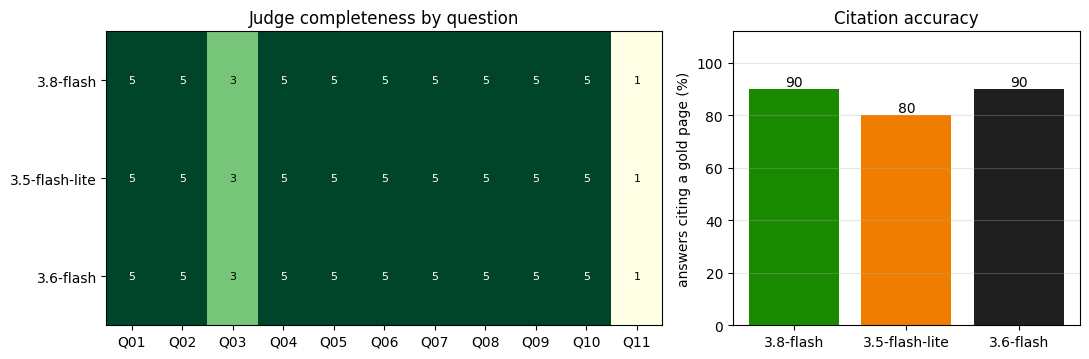

In [22]:
HUES = dict(zip(RUN["contenders"], ("#198A00", "#EF7D00", "#1F1F1F")))
per_question = RUN["bench_answers"].pivot(index="model", columns="qid", values="completeness").loc[RUN["contenders"]]
fig, (grid_ax, bar_ax) = plt.subplots(1, 2, figsize=(11, 3.7), gridspec_kw={"width_ratios": [1.6, 1]})
picture = grid_ax.imshow(per_question.to_numpy(float), cmap="YlGn", vmin=1, vmax=5, aspect="auto")
grid_ax.set(xticks=range(per_question.shape[1]), xticklabels=per_question.columns, yticks=range(3), title="Judge completeness by question")
grid_ax.set_yticklabels([m.replace("gemini-", "") for m in per_question.index])
for (y, x), mark in np.ndenumerate(per_question.to_numpy(float)):
    grid_ax.text(x, y, f"{mark:.0f}", ha="center", va="center", fontsize=8, color="white" if mark >= 4 else "black")
bars = bar_ax.bar([m.replace("gemini-", "") for m in league.index], league.gold_cited * 100, color=[HUES[m] for m in league.index])
bar_ax.bar_label(bars, fmt="%.0f")
bar_ax.set(ylim=(0, 112), ylabel="answers citing a gold page (%)", title="Citation accuracy")
bar_ax.grid(axis="y", alpha=.3)
fig.tight_layout()
fig.savefig(OUT / "extension.png", dpi=300, facecolor="white")
plt.show()

**Dashboard**  
In: the record, the parsed tables and the checks. Out: one page with a dark side panel, saved at 300 dpi.

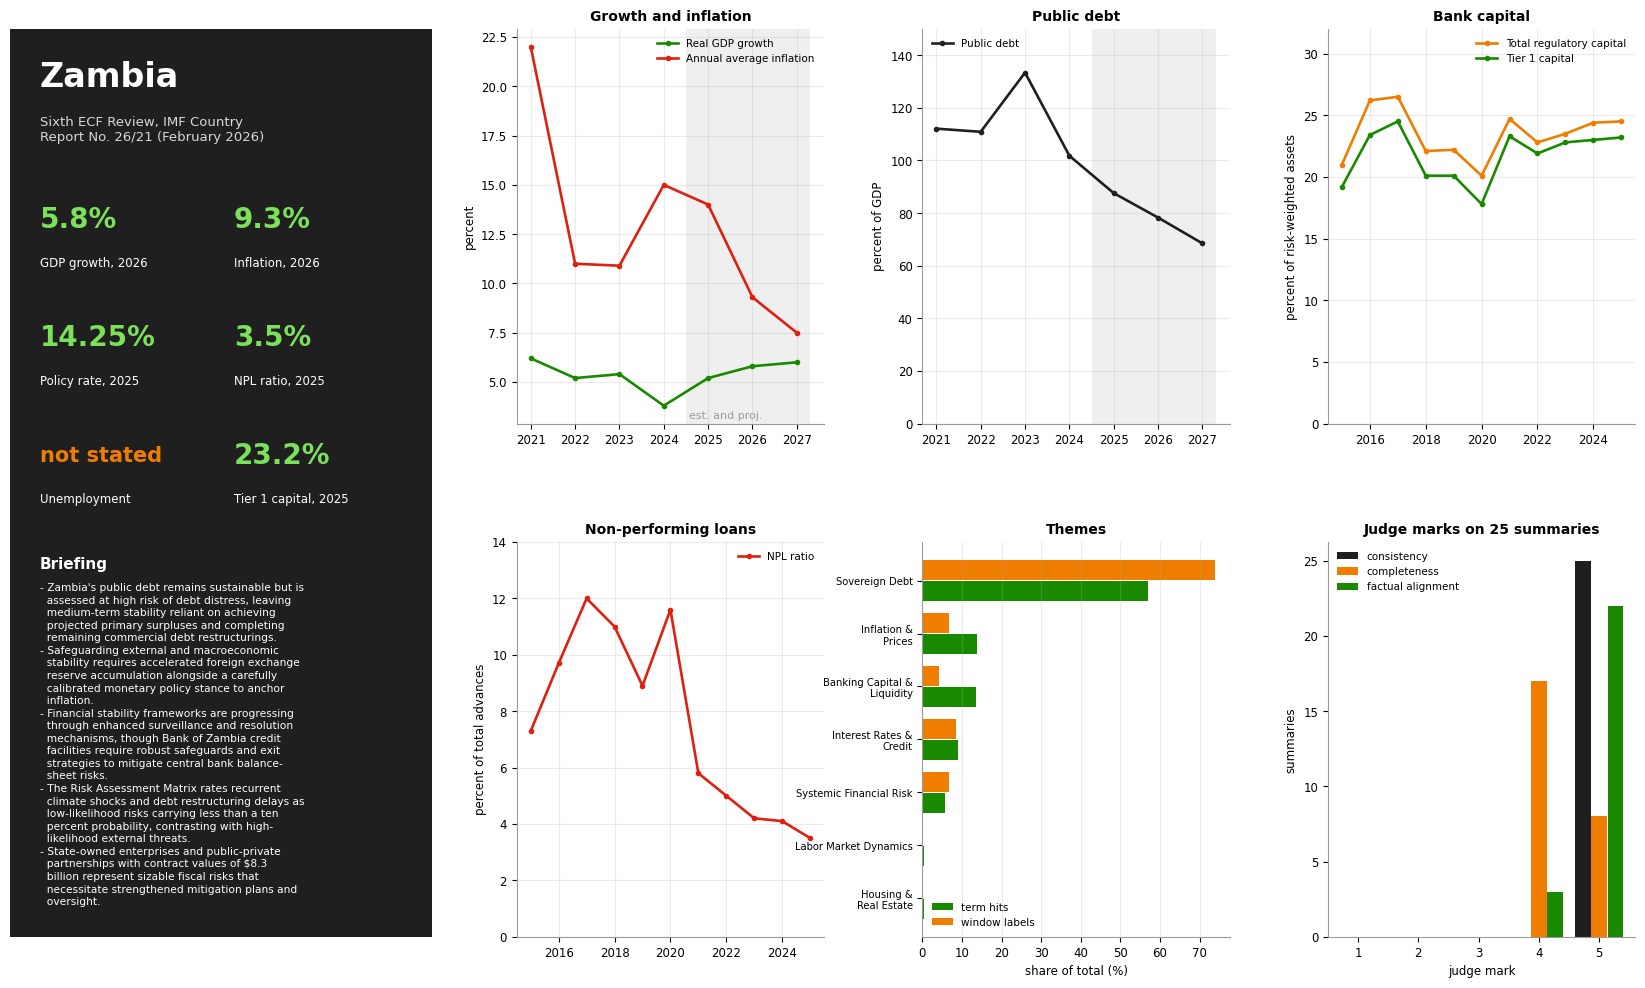

In [23]:
GREEN, RED, ORANGE, COAL, ASH, CHALK = "#198A00", "#DE2010", "#EF7D00", "#1F1F1F", "#9A9A9A", "#FFFFFF"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 8.5, "axes.titlesize": 10, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": ASH})
SHORT = {"gdp_growth_forecast_pct": "GDP growth", "headline_inflation_rate_pct": "Inflation", "central_bank_policy_rate_pct": "Policy rate", "non_performing_loan_ratio": "NPL ratio", "unemployment_rate_pct": "Unemployment", "tier_1_capital_ratio": "Tier 1 capital"}
macro, banks = RUN["macro"], RUN["banks"]


def melted(table, rename):
    return table.loc[list(rename)].rename(index=rename).rename_axis("series").reset_index().melt(id_vars="series", var_name="year", value_name="pct").dropna().astype({"year": int, "pct": float})


def draw(ax, frame, hues, projected=None):
    for name, part in frame.groupby("series", sort=False):
        ax.plot(part.year, part.pct, color=hues[name], lw=1.9, marker="o", ms=3, label=name)
    if projected:
        ax.axvspan(projected - .5, frame.year.max() + .3, color=ASH, alpha=.15, lw=0)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.grid(alpha=.25)
    ax.legend(frameon=False, fontsize=7.5)


label_of = lambda table, start: next(x for x in table.index if x.startswith(start))
fig = plt.figure(figsize=(16.5, 10.2), facecolor=CHALK)
outer = fig.add_gridspec(1, 2, width_ratios=[1, 2.65], wspace=.11, left=.0, right=.985, top=.955, bottom=.065)
side = fig.add_subplot(outer[0])
side.set_facecolor(COAL)
side.set(xticks=[], yticks=[], xlim=(0, 1), ylim=(0, 1))
side.spines[:].set_visible(False)
side.text(.07, .965, "Zambia", color=CHALK, fontsize=24, fontweight="bold", va="top")
side.text(.07, .905, "Sixth ECF Review, IMF Country\nReport No. 26/21 (February 2026)", color="#D8D8D8", fontsize=9.5, va="top")
for i, (field, name) in enumerate(SHORT.items()):
    x, y, value = .07 + (i % 2) * .46, .79 - (i // 2) * .13, RUN["record"][field]
    year = RUN["indicator_table"].set_index("field").year[field]
    side.text(x, y, "not stated" if value is None else f"{value:g}%", color=ORANGE if value is None else "#7BE05A", fontsize=15 if value is None else 20, fontweight="bold", va="center")
    side.text(x, y - .048, name if value is None else f"{name}, {int(year)}", color=CHALK, fontsize=8.5, va="center")
side.text(.07, .405, "Briefing", color=CHALK, fontsize=11, fontweight="bold")
side.text(.07, .39, "\n".join("\n".join(textwrap.wrap(b["sentence"], 50, initial_indent="- ", subsequent_indent="  ")) for b in RUN["briefing"]["bullets"][:5]), color=CHALK, fontsize=7.7, va="top", linespacing=1.32)

panels = outer[1].subgridspec(2, 3, hspace=.3, wspace=.32)
growth, debt, buffers, npl, themes_ax, judge_ax = [fig.add_subplot(panels[i, j]) for i in range(2) for j in range(3)]
year = whole("FORECAST_YEAR")
draw(growth, melted(macro, {label_of(macro, "Real GDP growth"): "Real GDP growth", label_of(macro, "Inflation annual"): "Annual average inflation"}), {"Real GDP growth": GREEN, "Annual average inflation": RED}, projected=year - 1)
growth.set(title="Growth and inflation", ylabel="percent")
growth.text(year - 1.42, growth.get_ylim()[0] + .25, "est. and proj.", color=ASH, fontsize=8)
draw(debt, melted(macro, {label_of(macro, "Public debt"): "Public debt"}), {"Public debt": COAL}, projected=year - 1)
debt.set(title="Public debt", ylabel="percent of GDP", ylim=(0, 150))
draw(buffers, melted(banks, {label_of(banks, "Regulatory capital to"): "Total regulatory capital", label_of(banks, "Tier 1 regulatory"): "Tier 1 capital"}), {"Total regulatory capital": ORANGE, "Tier 1 capital": GREEN})
buffers.set(title="Bank capital", ylabel="percent of risk-weighted assets", ylim=(0, 32))
draw(npl, melted(banks, {label_of(banks, "Past due advances"): "NPL ratio"}), {"NPL ratio": RED})
npl.set(title="Non-performing loans", ylabel="percent of total advances", ylim=(0, 14))

share = RUN["themes"]["table"].melt(id_vars="theme", value_vars=["term_share", "label_share"], var_name="method", value_name="pct")
order = RUN["themes"]["table"].sort_values("term_share").theme.tolist()
for offset, method, hue, name in ((-.2, "term_share", GREEN, "term hits"), (.2, "label_share", ORANGE, "window labels")):
    themes_ax.barh(np.arange(len(order)) + offset, share[share.method == method].set_index("theme").loc[order].pct, height=.38, color=hue, label=name)
themes_ax.set(yticks=range(len(order)), yticklabels=[t.replace(" & ", " &\n") for t in order], xlabel="share of total (%)", title="Themes")
themes_ax.tick_params(axis="y", labelsize=7.2)
themes_ax.legend(frameon=False, fontsize=7.5)
themes_ax.grid(axis="x", alpha=.25)

checks = pd.melt(marks[["consistency", "completeness", "factual_alignment"]], var_name="measure", value_name="mark").value_counts().rename("n").reset_index()
for offset, measure, hue in zip((-.27, 0, .27), ("consistency", "completeness", "factual_alignment"), (COAL, ORANGE, GREEN)):
    part = checks[checks.measure == measure]
    judge_ax.bar(part.mark + offset, part.n, width=.26, color=hue, label=measure.replace("_", " "))
judge_ax.set(xticks=range(1, 6), xlim=(.5, 5.6), xlabel="judge mark", ylabel="summaries", title=f"Judge marks on {len(marks)} summaries")
judge_ax.legend(frameon=False, fontsize=7.5, loc="upper left")
fig.savefig(OUT / "dashboard.png", dpi=300, facecolor=CHALK)
plt.show()

**Run record**  
In: every call made. Out: the call log and the prompt book.

In [24]:
calls = pd.DataFrame(LOG)
dump("call_log", {"writer": CFG["WRITER"], "judge": CFG["JUDGE"], "calls": len(calls), "live": int((calls.origin == "live").sum()), "stored": int((calls.origin == "stored").sum()), "redos": int(calls.step.str.endswith("+redo").sum()), "rows": calls})
dump("prompt_book", prompt_book())
print(f"{len(calls)} calls: {int((calls.origin == 'live').sum())} live, {int((calls.origin == 'stored').sum())} stored, {int(calls.step.str.endswith('+redo').sum())} redone")
calls.groupby("model").agg(calls=("step", "size"), seconds=("seconds", "mean"), tokens_in=("tokens_in", "sum"), tokens_out=("tokens_out", "sum")).round(2)

176 calls: 0 live, 176 stored, 1 redone


,calls,seconds,tokens_in,tokens_out
model,,,,
gemini-3.5-flash-lite,12,0.92,45140,1999
gemini-3.6-flash,12,4.83,45140,3106
gemini-3.7-flash,79,8.33,330027,8753
gemini-3.8-flash,73,18.98,326311,20233
